# 09. E2: Level Bloom, Heuristik vs Groq

Seberapa tepat heuristik dan Groq menebak level Bloom (L1 Mengingat sampai L6 Mencipta) dari sebuah jawaban?

- Heuristik menghitung penanda di teks (kata kerja Bloom, kata sebab-akibat, pembanding, penilaian, rancangan). Level tertinggi yang skornya minimal 2,0 yang dipilih. Jawaban pendek dibatasi levelnya.
- Groq gpt-oss-120b membaca jawaban dengan prompt produksi lalu memberi level 1 sampai 6.
- Di aplikasi, level dari Groq yang dipakai. Kalau keduanya berselisih 3 level atau lebih, dosen diminta mengecek sendiri.

Data: 10 soal x 6 level = 60 jawaban sekitar 300 kata yang dibuat dengan level yang diminta.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import hashlib
import os
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import notebook_kit as kit
from src.evaluate_baseline import bootstrap_backend

pd.set_option("display.max_colwidth", 70)

KEYS = kit.use_keys(groq_env="GROQ_API_KEY_BLOOM")
bootstrap_backend()
from apps.analysis.engines.bloom import BLOOM_LABELS, EVIDENCE_THRESHOLD, _length_cap, estimate_bloom_level
from apps.analysis.engines.text_features import extract_features
from apps.analysis.pipeline import BLOOM_DISAGREE_LEVELS
from apps.analysis.providers import groq as groq_judge

DATA = ROOT / "data" / "bloom" / "controlled_set.csv"
REVIEW = ROOT / "data" / "bloom" / "verifikasi.csv"
CACHE = ROOT / "data" / "cache" / "e2_bloom.jsonl"
OUT = kit.results_dir("e2_bloom")
TARGET_WORDS = 300
GEN_MODELS = ["openai/gpt-oss-20b", "qwen/qwen3-32b", "llama-3.1-8b-instant"]

Kunci: groq ada, winston ada


## 0. Contoh cara kerja heuristik

Dua contoh pendek untuk melihat alurnya: fitur, skor per level, ambang 2,0, batas panjang, lalu level akhir.

In [2]:
EXAMPLES = {
    "contoh A": "Inflasi adalah kenaikan harga barang dan jasa secara umum dalam periode tertentu. "
                "Inflasi diukur dengan indeks harga konsumen. Bank Indonesia bertugas menjaga inflasi. "
                "Jenis inflasi ada inflasi ringan, sedang, berat, dan hiperinflasi.",
    "contoh B": "Inflasi 2022 naik karena harga BBM disesuaikan, sehingga ongkos angkut barang ikut naik "
                "dan harga pangan terdorong. Namun, dampaknya tidak sama. Di kota, rumah tangga lebih banyak "
                "membeli makanan jadi sehingga lebih terpukul, sedangkan di desa sebagian pangan diproduksi "
                "sendiri. Dibandingkan inflasi 2008, kenaikan kali ini lebih cepat mereda karena subsidi "
                "dialihkan menjadi bantuan tunai. Oleh karena itu, bantuan sebaiknya dibedakan menurut wilayah.",
}

for name, text in EXAMPLES.items():
    features = extract_features(text)
    result = estimate_bloom_level(features)
    print(f"{name}: {features.word_count} kata, L{result.level} {result.label}")
    print("  skor  :", {f"L{k}": round(v, 1) for k, v in result.level_scores.items()}, f"(ambang {EVIDENCE_THRESHOLD})")
    print(f"  batas : maksimal L{_length_cap(features.word_count)}")
    print("  bukti :", result.evidence, "\n")

contoh A: 32 kata, L1 Mengingat
  skor  : {'L1': 0.0, 'L2': 0.0, 'L3': 0.0, 'L4': 0.0, 'L5': 0.0, 'L6': 0.0} (ambang 2.0)
  batas : maksimal L1
  bukti : ['Teks hanya 32 kata, terlalu pendek untuk menunjukkan level kognitif tinggi'] 

contoh B: 63 kata, L2 Memahami
  skor  : {'L1': 0.0, 'L2': 0.0, 'L3': 0.0, 'L4': 5.6, 'L5': 1.0, 'L6': 0.0} (ambang 2.0)
  batas : maksimal L2
  bukti : ['Ada 5 konektor sebab akibat, penanda penalaran', 'Ada 3 konektor pembandingan atau pertentangan', 'Ada 1 penanda sikap menilai', 'Level dibatasi maksimal L2 karena panjang teks 63 kata'] 



## 1. Data

Untuk tiap soal, model generator menulis satu jawaban pada satu level. Hasil disimpan per baris ke `data/bloom/controlled_set.csv`, jadi bisa dilanjutkan kalau terhenti. Lembar `verifikasi.csv` bisa diisi kolom `label_manusia` sebagai pembanding manusia.

In [3]:
QUESTIONS = [
    "Bagaimana inflasi memengaruhi daya beli rumah tangga di Indonesia?",
    "Apa peran fotosintesis bagi kehidupan di bumi?",
    "Bagaimana media sosial memengaruhi partisipasi politik anak muda?",
    "Mengapa struktur data hash table cepat untuk pencarian data?",
    "Bagaimana sampah plastik memengaruhi ekosistem laut?",
    "Apa dampak pembelajaran daring terhadap hasil belajar mahasiswa?",
    "Bagaimana prinsip permintaan dan penawaran menentukan harga cabai?",
    "Apa pentingnya vaksinasi bagi kesehatan masyarakat?",
    "Bagaimana urbanisasi memengaruhi kemacetan di kota besar?",
    "Apa risiko keamanan dari kata sandi yang lemah pada aplikasi kampus?",
]
LEVEL_GUIDE = {
    1: "hanya menyebutkan fakta, definisi, dan istilah yang diingat, tanpa penjelasan",
    2: "menjelaskan konsep dengan kata sendiri, merangkum, dan memberi contoh",
    3: "memakai konsep atau prosedur pada satu kasus konkret, langkah demi langkah",
    4: "menguraikan bagian-bagian, hubungan sebab-akibat, dan membandingkan",
    5: "menilai atau mempertimbangkan dengan kriteria dan alasan, lalu mengambil sikap",
    6: "merancang usulan atau solusi baru yang utuh, lengkap dengan langkah dan alasannya",
}
PROMPT = (
    "Tulis satu contoh jawaban mahasiswa S1 berbahasa Indonesia sekitar {words} kata untuk soal berikut.\n"
    "Soal: {question}\n"
    "Jawaban harus berada tepat pada level berpikir ini: {guide}. Jangan melampaui level ini. "
    "Tunjukkan level lewat isi jawaban, jangan menyebut nama level atau istilah taksonomi. "
    "Tulis dalam paragraf, tanpa judul dan tanpa poin-poin."
)


def build_controlled_set():
    columns = ["qid", "question", "target_level", "generator", "text"]
    done = pd.read_csv(DATA) if DATA.exists() else pd.DataFrame(columns=columns)
    have = set(zip(done.qid, done.target_level))
    todo = [(q, lvl) for q in range(len(QUESTIONS)) for lvl in LEVEL_GUIDE if (q, lvl) not in have]
    if not todo:
        return done
    models = [m for m in GEN_MODELS if m in kit.groq_models()]
    DATA.parent.mkdir(parents=True, exist_ok=True)
    for i, (qid, level) in enumerate(todo):
        model = models[i % len(models)]
        prompt = PROMPT.format(words=TARGET_WORDS, question=QUESTIONS[qid], guide=LEVEL_GUIDE[level])
        text = kit.with_retry(kit.groq_chat, prompt, model, max_tokens=1500)
        row = pd.DataFrame([{"qid": qid, "question": QUESTIONS[qid], "target_level": level, "generator": model, "text": text}])
        row.to_csv(DATA, mode="a", header=not DATA.exists(), index=False)
        print(f"Q{qid} L{level} dari {model}: {len(text.split())} kata")
    return pd.read_csv(DATA)


answers = build_controlled_set()
if not REVIEW.exists():
    answers.assign(label_manusia="")[["qid", "target_level", "label_manusia", "text"]].to_csv(REVIEW, index=False)
    print(f"Lembar cek manusia dibuat: {REVIEW}")
pd.crosstab(answers.qid, answers.target_level)

target_level,1,2,3,4,5,6
qid,,,,,,
0,1,1,1,1,1,1
1,1,1,1,1,1,1
2,1,1,1,1,1,1
3,1,1,1,1,1,1
4,1,1,1,1,1,1
5,1,1,1,1,1,1
6,1,1,1,1,1,1
7,1,1,1,1,1,1
8,1,1,1,1,1,1


## 2. Pra-pemrosesan

Jawaban harus 200 sampai 600 kata dan berbahasa Indonesia. Jawaban yang tidak lolos dikeluarkan.

In [4]:
features = answers.text.map(extract_features)
answers["words"] = [f.word_count for f in features]
answers["indonesian_ratio"] = [round(f.indonesian_ratio, 2) for f in features]
answers["ok"] = answers.words.between(200, 600) & (answers.indonesian_ratio >= 0.12)
print("dikeluarkan:", (~answers.ok).sum(), "dari", len(answers))
display(answers.groupby("target_level")[["words", "indonesian_ratio"]].mean().round(2))
data = answers[answers.ok].reset_index(drop=True)

dikeluarkan: 2 dari 60


,words,indonesian_ratio
target_level,,
1,313.6,0.19
2,253.1,0.22
3,235.2,0.21
4,248.2,0.22
5,238.3,0.22
6,259.4,0.21


## 3. Pengujian

Heuristik berjalan lokal. Groq dipanggil sekali per jawaban dan hasilnya disimpan di cache.

In [5]:
cache = kit.load_jsonl(CACHE)


def groq_level(text):
    # Prompt ikut di kunci: prompt produksi berubah berarti angka lama tidak berlaku lagi.
    key = hashlib.sha256((groq_judge.SYSTEM_PROMPT + text).encode()).hexdigest()[:16]
    if key not in cache:
        raw, seconds = kit.timed(kit.with_retry, groq_judge.call, text, "S1")
        cache[key] = {"level": int(raw["bloom_level"]), "seconds": round(seconds, 2)}
        kit.append_jsonl(CACHE, key, cache[key])
    return cache[key]


heuristic = [estimate_bloom_level(extract_features(t)) for t in data.text]
data["heuristik"] = [h.level for h in heuristic]
data["bukti_heuristik"] = ["; ".join(h.evidence[:2]) for h in heuristic]

if KEYS["groq"]:
    groq = [groq_level(t) for t in data.text]
    data["groq"] = [g["level"] for g in groq]
    data["detik_groq"] = [g["seconds"] for g in groq]
    data["dicek_dosen"] = (data.groq - data.heuristik).abs() >= BLOOM_DISAGREE_LEVELS
ESTIMATORS = [c for c in ("heuristik", "groq") if c in data]
data[["qid", "target_level", *ESTIMATORS]].head(12)

,qid,target_level,heuristik,groq
0,0,2,4,4
1,0,3,4,4
2,0,4,4,5
3,0,5,4,5
4,0,6,5,5
5,1,1,1,2
6,1,2,1,2
7,1,3,3,4
8,1,4,4,5
9,1,5,5,5


## 4. Hasil

- tepat: level sama persis dengan target
- selisih 1: meleset paling jauh satu level
- Spearman: apakah level ikut naik ketika target naik
- kappa kuadrat: kesepakatan yang menghukum meleset jauh lebih berat

In [6]:
def score(pred, truth):
    return {
        "n": len(truth),
        "tepat": (pred == truth).mean(),
        "selisih 1": ((pred - truth).abs() <= 1).mean(),
        "Spearman": pred.rank().corr(truth.rank()),
        "kappa kuadrat": kit.quadratic_kappa(truth.astype(int).tolist(), pred.astype(int).tolist()),
    }


table = pd.DataFrame({e: score(data[e], data.target_level) for e in ESTIMATORS}).T

human = pd.read_csv(REVIEW) if REVIEW.exists() else pd.DataFrame()
if not human.empty:
    human = human[pd.to_numeric(human.label_manusia, errors="coerce").between(1, 6)]
if len(human) >= 10:
    merged = data.merge(human[["qid", "target_level", "label_manusia"]], on=["qid", "target_level"])
    merged["label_manusia"] = merged.label_manusia.astype(int)
    for e in ESTIMATORS:
        table.loc[f"{e} vs manusia"] = score(merged[e], merged.label_manusia)
table.round(3)

,n,tepat,selisih 1,Spearman,kappa kuadrat
heuristik,58.0,0.276,0.690,0.571,0.430
groq,58.0,0.310,0.741,0.761,0.558


In [7]:
per_level = data.groupby("target_level")[ESTIMATORS].agg(lambda s: (s == data.loc[s.index, "target_level"]).mean())
per_level.index = [f"L{i} {BLOOM_LABELS[i]}" for i in per_level.index]
per_level.round(2)

,heuristik,groq
L1 Mengingat,0.22,0.00
L2 Memahami,0.00,0.10
L3 Menerapkan,0.10,0.10
L4 Menganalisis,0.90,0.30
L5 Mengevaluasi,0.33,0.78
L6 Mencipta,0.10,0.60


## 5. Perbandingan

Matriks kebingungan menunjukkan ke level mana tebakan meleset. Tabel di bawahnya berisi jawaban yang dinilai sangat berbeda oleh heuristik dan Groq.

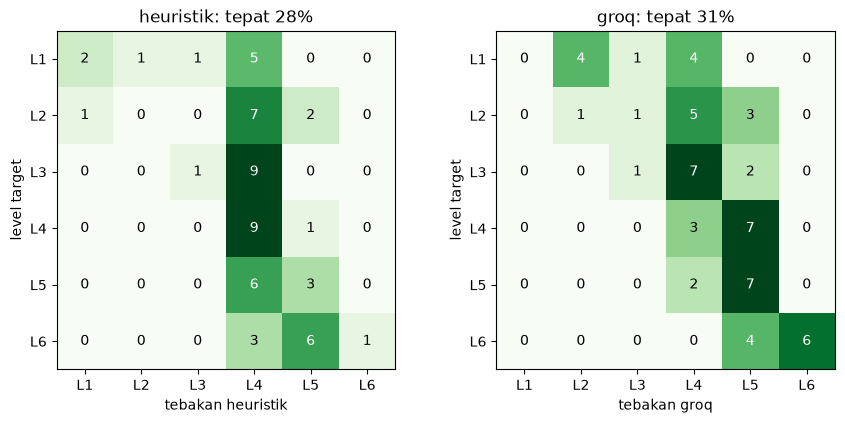

In [8]:
fig, axes = plt.subplots(1, len(ESTIMATORS), figsize=(5.2 * len(ESTIMATORS), 4.4), squeeze=False)
for ax, name in zip(axes[0], ESTIMATORS):
    matrix = pd.crosstab(data.target_level, data[name]).reindex(index=range(1, 7), columns=range(1, 7), fill_value=0)
    ax.imshow(matrix, cmap="Greens")
    for (i, j), v in np.ndenumerate(matrix.values):
        ax.text(j, i, v, ha="center", va="center", color="black" if v < matrix.values.max() / 2 else "white")
    ax.set_xticks(range(6), [f"L{i}" for i in range(1, 7)])
    ax.set_yticks(range(6), [f"L{i}" for i in range(1, 7)])
    ax.set_xlabel(f"tebakan {name}")
    ax.set_ylabel("level target")
    ax.set_title(f"{name}: tepat {table.loc[name, 'tepat']:.0%}")
kit.save_figure(fig, "e2_bloom_kebingungan.png")
plt.show()

In [9]:
if "groq" in data:
    agree = (data.groq == data.heuristik).mean()
    print(f"Groq dan heuristik sama persis pada {agree:.0%} jawaban, {data.dicek_dosen.sum()} jawaban ditandai untuk dicek dosen.")
    display(data[data.dicek_dosen][["qid", "target_level", "heuristik", "groq", "bukti_heuristik"]])

Groq dan heuristik sama persis pada 43% jawaban, 0 jawaban ditandai untuk dicek dosen.


,qid,target_level,heuristik,groq,bukti_heuristik


## 6. Kesimpulan

Jawaban dibuat model dengan level yang diminta, bukan jawaban mahasiswa asli. Hasil ini menunjukkan kemampuan membedakan level pada teks terkendali, belum akurasi pada tugas sungguhan.

In [10]:
data.drop(columns="text").to_csv(OUT / "per_jawaban.csv", index=False)
table.round(4).to_csv(OUT / "metrik.csv")

kit.write_summary(OUT / "ringkasan.md", "E2: level Bloom, heuristik vs Groq", {
    "Data": f"{len(data)} jawaban terkontrol ({len(QUESTIONS)} soal x 6 level, sekitar {TARGET_WORDS} kata), "
            f"generator: {', '.join(sorted(set(data.generator)))}.",
    "Metrik": kit.md_table(table.round(3).rename_axis("penilai")),
    "Akurasi per level": kit.md_table(per_level.round(2).rename_axis("level")),
    "Batasan": "- Jawaban dibuat model, bukan jawaban mahasiswa asli.\n"
               "- Label target belum tentu sama dengan penilaian dosen kecuali label_manusia diisi.",
})
print((OUT / "ringkasan.md").read_text())

# E2: level Bloom, heuristik vs Groq

## Data

58 jawaban terkontrol (10 soal x 6 level, sekitar 300 kata), generator: openai/gpt-oss-20b.

## Metrik

| penilai | n | tepat | selisih 1 | Spearman | kappa kuadrat |
|---|---|---|---|---|---|
| heuristik | 58.0 | 0.276 | 0.69 | 0.571 | 0.43 |
| groq | 58.0 | 0.31 | 0.741 | 0.761 | 0.558 |

## Akurasi per level

| level | heuristik | groq |
|---|---|---|
| L1 Mengingat | 0.22 | 0.0 |
| L2 Memahami | 0.0 | 0.1 |
| L3 Menerapkan | 0.1 | 0.1 |
| L4 Menganalisis | 0.9 | 0.3 |
| L5 Mengevaluasi | 0.33 | 0.78 |
| L6 Mencipta | 0.1 | 0.6 |

## Batasan

- Jawaban dibuat model, bukan jawaban mahasiswa asli.
- Label target belum tentu sama dengan penilaian dosen kecuali label_manusia diisi.

